# Bike Rental Demand Prediction

## Project Objective
The objective of this project is to analyze hourly bike rental demand, identify patterns associated with demand, and build and evaluate regression models to predict the number of bike rentals.

## Dataset
The project uses the original UCI Bike Sharing Dataset, containing hourly bike rental counts and corresponding seasonal, calendar, and weather information from Washington, D.C., during 2011–2012.

## Project Workflow
1. Data loading and inspection
2. Exploratory data analysis (EDA)
3. Data cleaning and feature preparation
4. Chronological train-test split and rolling validation
5. Baseline model and Random Forest Regressor
6. Evaluation using MAE, RMSE, WMAPE, and mean error
7. Prediction error and bias analysis
8. Comparison with a model using a Poisson objective
9. Findings, limitations, and conclusions

In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Fetch the original UCI Bike Sharing Dataset
bike_sharing = fetch_ucirepo(id=275)

# Get the features and target
X = bike_sharing.data.features
y = bike_sharing.data.targets

# Combine them into one DataFrame
df = X.copy()
df["cnt"] = y["cnt"].values

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (17379, 14)

Columns:
['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1


In [3]:
df = df.rename(columns={
    "dteday": "date",
    "yr": "year",
    "mnth": "month",
    "hr": "hour",
    "weathersit": "weather",
    "hum": "humidity",
    "cnt": "demand"
})

print(df.columns.tolist())
display(df.head())

['date', 'season', 'year', 'month', 'hour', 'holiday', 'weekday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'demand']


,date,season,year,month,hour,holiday,weekday,workingday,weather,temp,atemp,humidity,windspeed,demand
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1


In [4]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

Dataset shape: (17379, 14)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        17379 non-null  object 
 1   season      17379 non-null  int64  
 2   year        17379 non-null  int64  
 3   month       17379 non-null  int64  
 4   hour        17379 non-null  int64  
 5   holiday     17379 non-null  int64  
 6   weekday     17379 non-null  int64  
 7   workingday  17379 non-null  int64  
 8   weather     17379 non-null  int64  
 9   temp        17379 non-null  float64
 10  atemp       17379 non-null  float64
 11  humidity    17379 non-null  float64
 12  windspeed   17379 non-null  float64
 13  demand      17379 non-null  int64  
dtypes: float64(4), int64(9), object(1)
memory usage: 1.9+ MB


In [5]:
print("\nMissing values:")
print(df.isnull().sum())



Missing values:
date          0
season        0
year          0
month         0
hour          0
holiday       0
weekday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
demand        0
dtype: int64


In [6]:
print("\nSummary statistics:")
display(df.describe())


Summary statistics:


,season,year,month,hour,holiday,weekday,workingday,weather,temp,atemp,humidity,windspeed,demand
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,189.463088
std,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,181.387599
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,40.000000
50%,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,142.000000
75%,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,281.000000
max,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,977.000000


#### Convert the date column

In [7]:
df["date"] = pd.to_datetime(df["date"])

print("Date data type:", df["date"].dtype)

print("First date:", df["date"].min())
print("Last date:", df["date"].max())

print("Already chronological:", df["date"].is_monotonic_increasing)

Date data type: datetime64[ns]
First date: 2011-01-01 00:00:00
Last date: 2012-12-31 00:00:00
Already chronological: True


## Exploratory Data Analysis (EDA)

#### average demand by hour

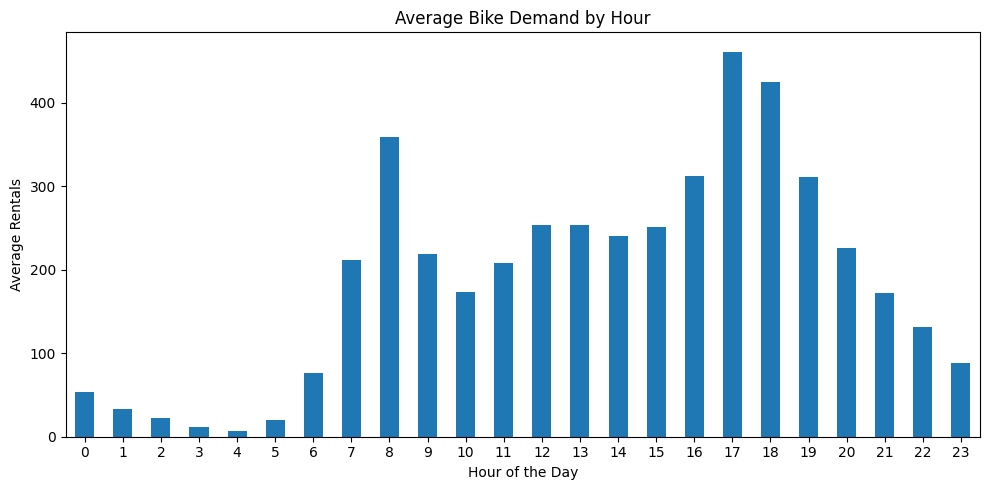

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

hourly_demand = df.groupby("hour")["demand"].mean()

hourly_demand.plot(kind="bar", figsize=(10, 5))

plt.title("Average Bike Demand by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Average demand by weekday

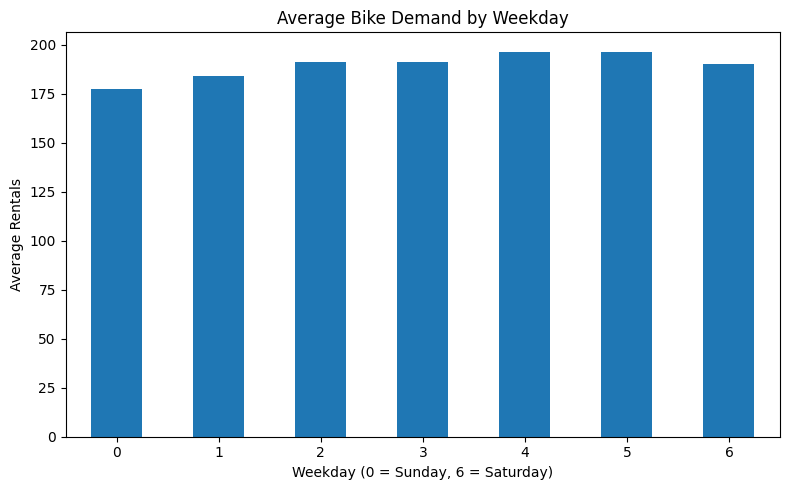

In [9]:
weekday_demand = df.groupby("weekday")["demand"].mean()

weekday_demand.plot(kind="bar", figsize=(8, 5))

plt.title("Average Bike Demand by Weekday")
plt.xlabel("Weekday (0 = Sunday, 6 = Saturday)")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
weekday_demand = df.groupby("weekday")["demand"].mean()

print("Average demand by weekday:")
print(weekday_demand.round(2))

Average demand by weekday:
weekday
0    177.47
1    183.74
2    191.24
3    191.13
4    196.44
5    196.14
6    190.21
Name: demand, dtype: float64


Insight: Average hourly demand is slightly higher toward the end of the week and lower on Sunday, but the difference isn't huge.

#### Average demand by working day

Average demand by working day:
workingday
0    181.41
1    193.21
Name: demand, dtype: float64


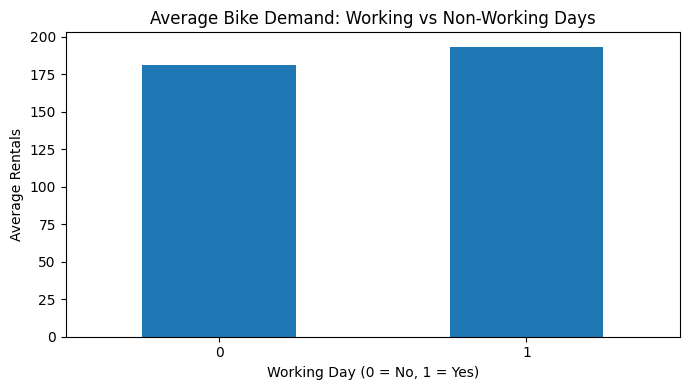

In [11]:
# Calculate average demand by working day
workingday_demand = df.groupby("workingday")["demand"].mean()

print("Average demand by working day:")
print(workingday_demand.round(2))

# Plot the graph
workingday_demand.plot(kind="bar", figsize=(7, 4))

plt.title("Average Bike Demand: Working vs Non-Working Days")
plt.xlabel("Working Day (0 = No, 1 = Yes)")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Insight: Bike demand is somewhat higher on working days, which may indicate commuting-related usage.

#### Average demand by weather

Average demand by weather condition:
weather
Clear / Few Clouds          204.87
Mist / Cloudy               175.17
Light Rain / Snow           111.58
Heavy Rain / Ice Pellets     74.33
Name: demand, dtype: float64


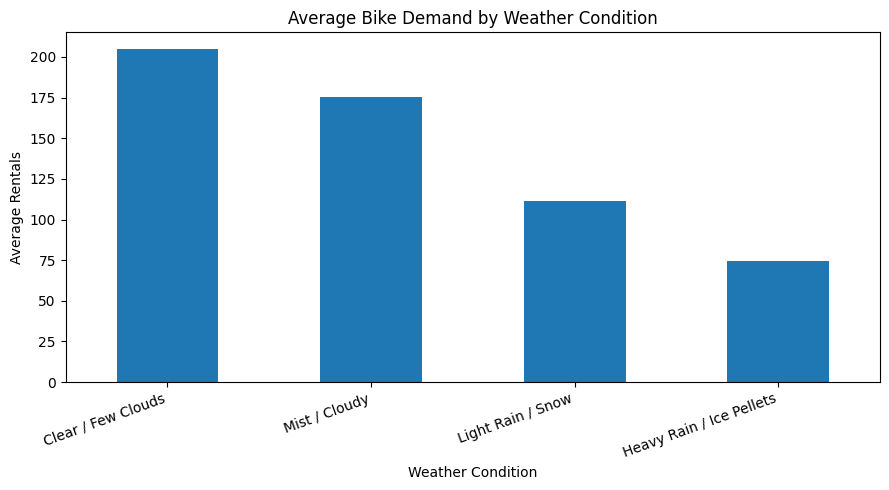

In [12]:
# Map weather codes to readable labels
weather_labels = {
    1: "Clear / Few Clouds",
    2: "Mist / Cloudy",
    3: "Light Rain / Snow",
    4: "Heavy Rain / Ice Pellets"
}

weather_demand = df.groupby("weather")["demand"].mean().round(2)

weather_demand.index = weather_demand.index.map(weather_labels)

print("Average demand by weather condition:")
print(weather_demand)

weather_demand.plot(kind="bar", figsize=(9, 5))

plt.title("Average Bike Demand by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Rentals")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Insight: Average demand decreases as weather conditions become more severe. This suggests weather is a useful feature to consider when predicting bike rentals.

#### Average demand by season

Average demand by season:
season
Spring    111.11
Summer    208.34
Fall      236.02
Winter    198.87
Name: demand, dtype: float64


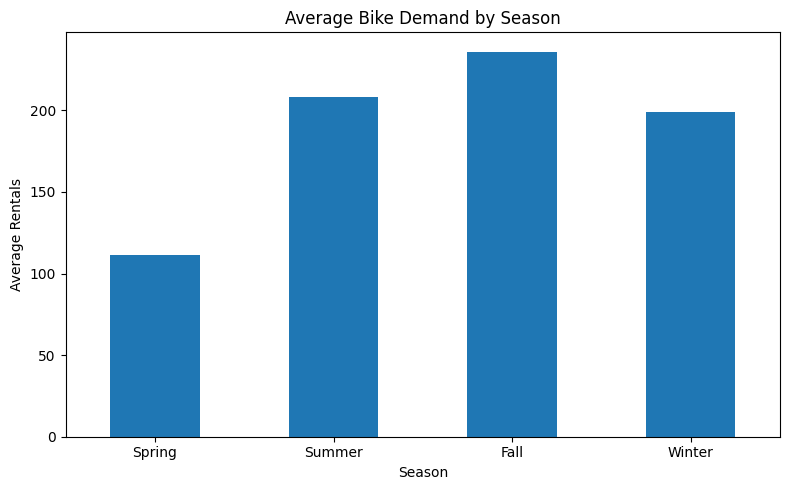

In [13]:
# Map season codes to readable labels
season_labels = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}

season_demand = df.groupby("season")["demand"].mean().round(2)

season_demand.index = season_demand.index.map(season_labels)

print("Average demand by season:")
print(season_demand)

season_demand.plot(kind="bar", figsize=(8, 5))

plt.title("Average Bike Demand by Season")
plt.xlabel("Season")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Insight: Average bike rental demand is highest in fall and lowest in spring. Season appears to be a useful feature for predicting demand.

#### Average demand by month

Average demand by month:
month
1      94.42
2     112.87
3     155.41
4     187.26
5     222.91
6     240.52
7     231.82
8     238.10
9     240.77
10    222.16
11    177.34
12    142.30
Name: demand, dtype: float64


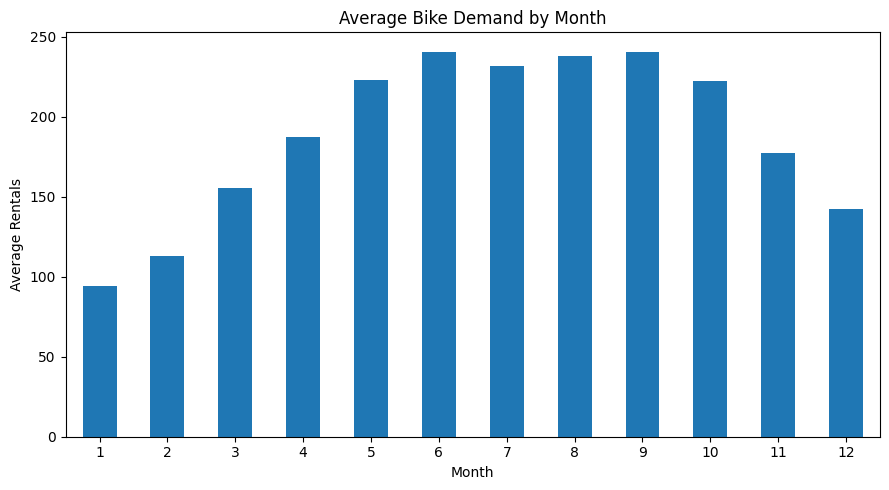

In [14]:
monthly_demand = df.groupby("month")["demand"].mean().round(2)

print("Average demand by month:")
print(monthly_demand)

monthly_demand.plot(kind="bar", figsize=(9, 5))

plt.title("Average Bike Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Insight: Month appears to be an important predictor of bike rental demand. The pattern also supports what we observed in the seasonal analysis.

#### Average demand by temperature

Average demand by temperature range:
temp_group
0–0.2       65.07
0.2–0.4    123.07
0.4–0.6    194.67
0.6–0.8    260.70
0.8–1.0    326.28
Name: demand, dtype: float64


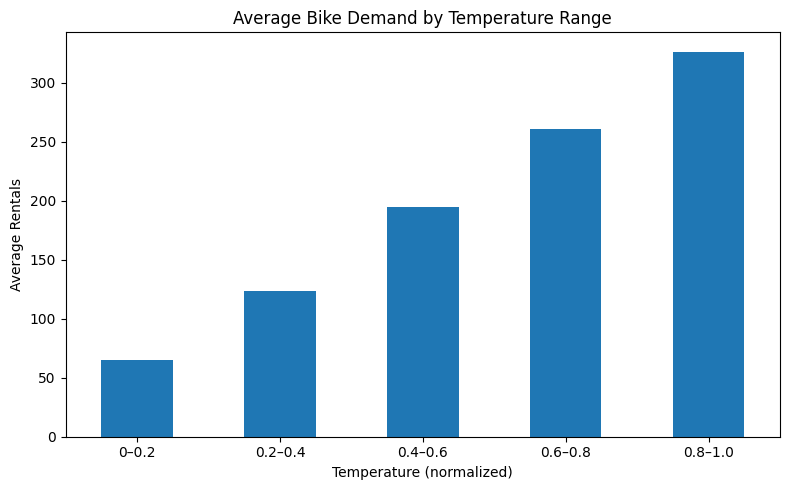

In [15]:
# Group temperature into ranges for easier interpretation
df["temp_group"] = pd.cut(
    df["temp"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=["0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.8", "0.8–1.0"],
    include_lowest=True
)

# Calculate average demand for each temperature range
temp_demand = df.groupby("temp_group", observed=False)["demand"].mean().round(2)

print("Average demand by temperature range:")
print(temp_demand)

temp_demand.plot(kind="bar", figsize=(8, 5))

plt.title("Average Bike Demand by Temperature Range")
plt.xlabel("Temperature (normalized)")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Insight: Higher temperatures are associated with higher bike rental demand in this dataset. Temperature may be a useful predictor for our model.

#### Average demand by humidity

Average demand by humidity range:
humidity_group
0–0.2      225.95
0.2–0.4    288.11
0.4–0.6    221.75
0.6–0.8    172.90
0.8–1.0    107.24
Name: demand, dtype: float64


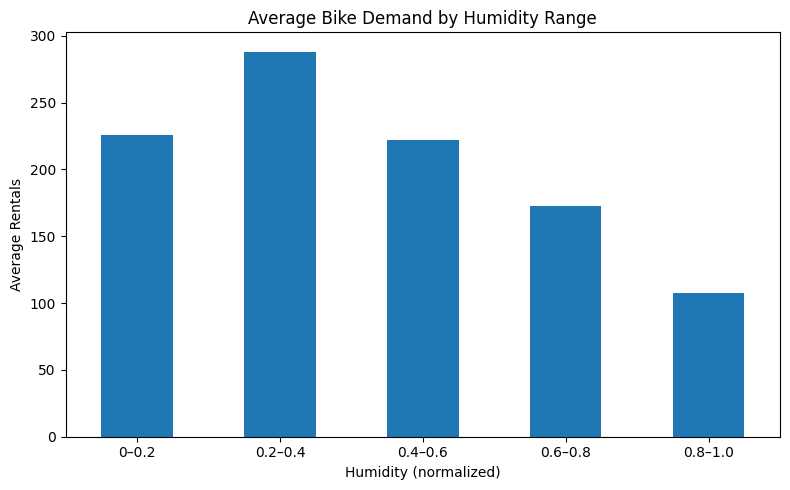

In [16]:
# Group humidity into ranges
df["humidity_group"] = pd.cut(
    df["humidity"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=["0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.8", "0.8–1.0"],
    include_lowest=True
)

# Calculate average demand
humidity_demand = df.groupby(
    "humidity_group", observed=False
)["demand"].mean().round(2)

print("Average demand by humidity range:")
print(humidity_demand)

humidity_demand.plot(kind="bar", figsize=(8, 5))

plt.title("Average Bike Demand by Humidity Range")
plt.xlabel("Humidity (normalized)")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Higher humidity ranges generally showed lower demand, suggesting humidity may help explain rental patterns.

#### Average demand by windspeed

Average demand by windspeed range:
windspeed_group
0–0.2      175.01
0.2–0.4    212.44
0.4–0.6    201.55
0.6–0.8    156.50
0.8–1.0    152.40
Name: demand, dtype: float64


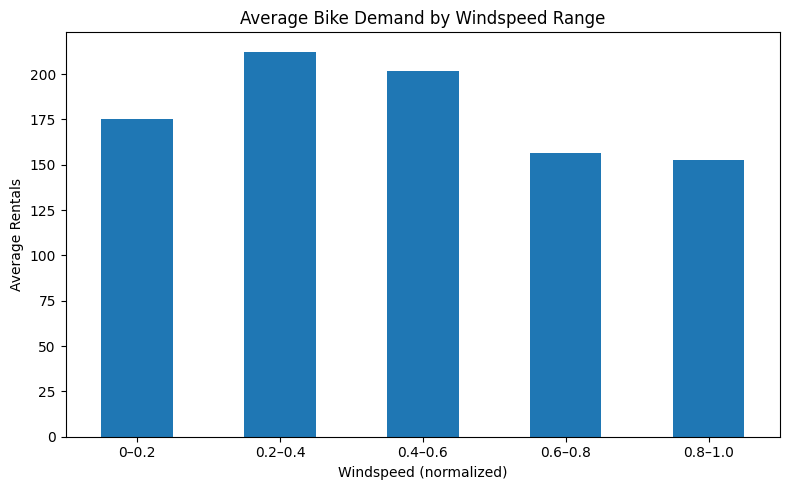

In [17]:
# Group windspeed into ranges
df["windspeed_group"] = pd.cut(
    df["windspeed"],
    bins=[-0.01, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=["0–0.2", "0.2–0.4", "0.4–0.6", "0.6–0.8", "0.8–1.0"]
)

# Calculate average demand
windspeed_demand = df.groupby(
    "windspeed_group", observed=False
)["demand"].mean().round(2)

print("Average demand by windspeed range:")
print(windspeed_demand)

windspeed_demand.plot(kind="bar", figsize=(8, 5))

plt.title("Average Bike Demand by Windspeed Range")
plt.xlabel("Windspeed (normalized)")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
print("Duplicate date-hour records:",
      df.duplicated(subset=["date", "hour"]).sum())

print("\nSeason counts:")
print(df["season"].value_counts().sort_index())

print("\nWeather counts:")
print(df["weather"].value_counts().sort_index())

print("\nDemand range:")
print("Minimum:", df["demand"].min())
print("Maximum:", df["demand"].max())

Duplicate date-hour records: 0

Season counts:
season
1    4242
2    4409
3    4496
4    4232
Name: count, dtype: int64

Weather counts:
weather
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64

Demand range:
Minimum: 1
Maximum: 977


## Define our prediction target and features

In [19]:
# Columns we will use as predictors
feature_columns = [
    "season",
    "year",
    "month",
    "hour",
    "holiday",
    "weekday",
    "workingday",
    "weather",
    "temp",
    "atemp",
    "humidity",
    "windspeed"
]

# Define features (X) and target (y)
X = df[feature_columns]
y = df["demand"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget preview:")
print(y.head())

Features shape: (17379, 12)
Target shape: (17379,)

Feature columns:
['season', 'year', 'month', 'hour', 'holiday', 'weekday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed']

Target preview:
0    16
1    40
2    32
3    13
4     1
Name: demand, dtype: int64


In [20]:
# Calculate chronological split boundaries
n = len(df)

train_end = int(n * 0.60)
test_start = int(n * 0.80)

# Development data: first 80%
X_dev = X.iloc[:test_start].copy()
y_dev = y.iloc[:test_start].copy()

# Final test data: last 20%
X_test = X.iloc[test_start:].copy()
y_test = y.iloc[test_start:].copy()

print("Initial training history:", train_end, "rows")
print("Development data:", X_dev.shape[0], "rows")
print("Final test data:", X_test.shape[0], "rows")

print("\nInitial training period:")
print(df["date"].iloc[0], "to", df["date"].iloc[train_end - 1])

print("\nDevelopment period ends:")
print(df["date"].iloc[test_start - 1])

print("\nFinal test period:")
print(df["date"].iloc[test_start], "to", df["date"].iloc[-1])

Initial training history: 10427 rows
Development data: 13903 rows
Final test data: 3476 rows

Initial training period:
2011-01-01 00:00:00 to 2012-03-15 00:00:00

Development period ends:
2012-08-07 00:00:00

Final test period:
2012-08-07 00:00:00 to 2012-12-31 00:00:00


Check the split boundary

In [21]:
print("Last 5 development records:")
print(df.iloc[test_start - 5:test_start][["date", "hour", "demand"]])

print("\nFirst 5 test records:")
print(df.iloc[test_start:test_start + 5][["date", "hour", "demand"]])

Last 5 development records:
            date  hour  demand
13898 2012-08-07     7     502
13899 2012-08-07     8     705
13900 2012-08-07     9     327
13901 2012-08-07    10     250
13902 2012-08-07    11     214

First 5 test records:
            date  hour  demand
13903 2012-08-07    12     283
13904 2012-08-07    13     253
13905 2012-08-07    14     261
13906 2012-08-07    15     306
13907 2012-08-07    16     445


Create expanding-window validation folds

In [22]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=3)

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_dev), start=1):
    print(f"\nFold {fold}")
    print("Training rows:", len(train_idx))
    print("Validation rows:", len(val_idx))

    print(
        "Training period:",
        df["date"].iloc[train_idx[0]],
        "to",
        df["date"].iloc[train_idx[-1]]
    )

    print(
        "Validation period:",
        df["date"].iloc[val_idx[0]],
        "to",
        df["date"].iloc[val_idx[-1]]
    )


Fold 1
Training rows: 3478
Validation rows: 3475
Training period: 2011-01-01 00:00:00 to 2011-05-29 00:00:00
Validation period: 2011-05-29 00:00:00 to 2011-10-22 00:00:00

Fold 2
Training rows: 6953
Validation rows: 3475
Training period: 2011-01-01 00:00:00 to 2011-10-22 00:00:00
Validation period: 2011-10-22 00:00:00 to 2012-03-15 00:00:00

Fold 3
Training rows: 10428
Validation rows: 3475
Training period: 2011-01-01 00:00:00 to 2012-03-15 00:00:00
Validation period: 2012-03-15 00:00:00 to 2012-08-07 00:00:00


## Baseline using the training mean

In [23]:

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

tscv = TimeSeriesSplit(n_splits=3)
baseline_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_dev), start=1):
    y_fold_train = y_dev.iloc[train_idx]
    y_fold_val = y_dev.iloc[val_idx]

    # Baseline prediction: training-set mean
    predictions = np.full(len(val_idx), y_fold_train.mean())

    mae = mean_absolute_error(y_fold_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_fold_val, predictions))

    # Weighted mean absolute percentage error
    wmape = (
        np.abs(y_fold_val.to_numpy() - predictions).sum()
        / np.abs(y_fold_val.to_numpy()).sum()
    ) * 100

    # Signed mean error: positive = overprediction
    mean_error = np.mean(predictions - y_fold_val.to_numpy())

    baseline_results.append({
        "Fold": fold,
        "Training Mean": round(y_fold_train.mean(), 2),
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "WMAPE (%)": round(wmape, 2),
        "Mean Error": round(mean_error, 2)
    })

baseline_results = pd.DataFrame(baseline_results)

print(baseline_results)
print("\nAverage across folds:")
print(baseline_results[["MAE", "RMSE", "WMAPE (%)", "Mean Error"]].mean().round(2))


   Fold  Training Mean     MAE    RMSE  WMAPE (%)  Mean Error
0     1         107.05  127.81  169.00      68.74      -78.89
1     2         146.47  103.52  129.82      73.18        5.00
2     3         144.81  187.68  246.37      71.05     -119.35

Average across folds:
MAE           139.67
RMSE          181.73
WMAPE (%)      70.99
Mean Error    -64.41
dtype: float64


## Train and validate Random Forest

In [24]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

tscv = TimeSeriesSplit(n_splits=3)
rf_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_dev), start=1):

    X_fold_train = X_dev.iloc[train_idx]
    X_fold_val = X_dev.iloc[val_idx]

    y_fold_train = y_dev.iloc[train_idx]
    y_fold_val = y_dev.iloc[val_idx]

    # Create and train the Random Forest model
    rf_model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    rf_model.fit(X_fold_train, y_fold_train)

    predictions = rf_model.predict(X_fold_val)

    mae = mean_absolute_error(y_fold_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_fold_val, predictions))

    actual = y_fold_val.to_numpy()

    wmape = (
        np.abs(actual - predictions).sum()
        / np.abs(actual).sum()
    ) * 100

    mean_error = np.mean(predictions - actual)

    rf_results.append({
        "Fold": fold,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "WMAPE (%)": round(wmape, 2),
        "Mean Error": round(mean_error, 2)
    })

rf_results = pd.DataFrame(rf_results)

print(rf_results)
print("\nAverage across folds:")
print(
    rf_results[["MAE", "RMSE", "WMAPE (%)", "Mean Error"]]
    .mean()
    .round(2)
)

   Fold    MAE    RMSE  WMAPE (%)  Mean Error
0     1  33.54   53.08      18.04        3.10
1     2  55.47   85.17      39.21      -33.21
2     3  71.34  100.56      27.01      -63.79

Average across folds:
MAE           53.45
RMSE          79.60
WMAPE (%)     28.09
Mean Error   -31.30
dtype: float64


#### Tune Random Forest using expanding-window validation

In [25]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
from itertools import product
import numpy as np
import pandas as pd

tscv = TimeSeriesSplit(n_splits=3)
tuning_results = []

# The 8 hyperparameter combinations
configurations = list(product(
    [None, 15],  # max_depth
    [1, 2],      # min_samples_leaf
    [2, 10]      # min_samples_split
))

for max_depth, min_leaf, min_split in configurations:

    fold_metrics = []

    for fold, (train_idx, val_idx) in enumerate(tscv.split(X_dev), start=1):

        X_fold_train = X_dev.iloc[train_idx]
        X_fold_val = X_dev.iloc[val_idx]
        y_fold_train = y_dev.iloc[train_idx]
        y_fold_val = y_dev.iloc[val_idx]

        model = RandomForestRegressor(
            n_estimators=100,
            max_depth=max_depth,
            min_samples_leaf=min_leaf,
            min_samples_split=min_split,
            random_state=42,
            n_jobs=-1
        )

        # Train on this fold's training history
        model.fit(X_fold_train, y_fold_train)

        # Evaluate on the next unseen block
        predictions = model.predict(X_fold_val)
        actual = y_fold_val.to_numpy()

        fold_metrics.append({
            "MAE": mean_absolute_error(actual, predictions),
            "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
            "WMAPE (%)": (
                np.abs(actual - predictions).sum()
                / np.abs(actual).sum()
            ) * 100,
            "Mean Error": np.mean(predictions - actual)
        })

    # Average each metric across the three folds
    avg_metrics = pd.DataFrame(fold_metrics).mean()

    tuning_results.append({
        "max_depth": max_depth,
        "min_samples_leaf": min_leaf,
        "min_samples_split": min_split,
        **avg_metrics.to_dict()
    })

tuning_results = pd.DataFrame(tuning_results)
tuning_results = tuning_results.sort_values("MAE").reset_index(drop=True)

print(tuning_results.round(2).to_string(index=False))


 max_depth  min_samples_leaf  min_samples_split   MAE  RMSE  WMAPE (%)  Mean Error
       NaN                 1                  2 53.45 79.60      28.08      -31.30
      15.0                 1                  2 53.54 79.71      28.11      -31.26
       NaN                 2                  2 53.59 79.98      28.13      -31.84
      15.0                 2                  2 53.72 80.11      28.18      -31.86
       NaN                 1                 10 54.24 80.27      28.50      -32.55
      15.0                 1                 10 54.26 80.29      28.51      -32.48
       NaN                 2                 10 54.29 80.54      28.49      -32.85
      15.0                 2                 10 54.37 80.64      28.52      -32.93


#### train the final model

In [26]:

from sklearn.ensemble import RandomForestRegressor

final_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_dev, y_dev)

print("Final model trained successfully.")
print("Training rows:", len(X_dev))
print("Final test rows:", len(X_test))

Final model trained successfully.
Training rows: 13903
Final test rows: 3476


#### Make predictions and evaluate the model

In [27]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict demand for the unseen test data
y_pred = final_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
wmape = (
    np.abs(y_test.to_numpy() - y_pred).sum()
    / np.abs(y_test.to_numpy()).sum()
) * 100

mean_error = np.mean(y_pred - y_test.to_numpy())

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"WMAPE: {wmape:.2f}%")
print(f"Mean Error: {mean_error:.2f}")

MAE: 44.99
RMSE: 69.56
WMAPE: 18.09%
Mean Error: -16.48


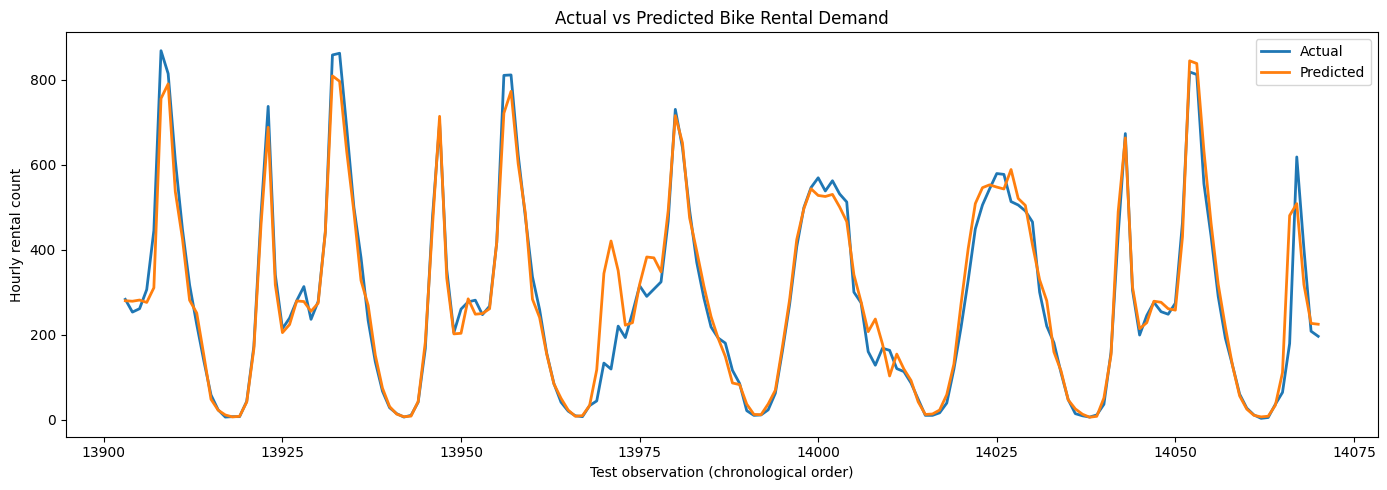

In [28]:
comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
}, index=X_test.index)

# Plot a small chronological sample for readability
sample = comparison.iloc[:168]  # First 7 days of the test set

plt.figure(figsize=(14, 5))
plt.plot(sample.index, sample["Actual"], label="Actual", linewidth=2)
plt.plot(sample.index, sample["Predicted"], label="Predicted", linewidth=2)

plt.title("Actual vs Predicted Bike Rental Demand")
plt.xlabel("Test observation (chronological order)")
plt.ylabel("Hourly rental count")
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
error_analysis = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
}, index=y_test.index)

error_analysis["Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
)

error_analysis["Absolute_Error"] = (
    error_analysis["Error"].abs()
)

In [ ]:

# Add the original date and feature values to the error table
columns_to_check = [
    "date", "hour", "season", "month", "weekday",
    "workingday", "weather", "temp", "humidity", "windspeed"
]

error_details = error_analysis.join(
    df.loc[error_analysis.index, columns_to_check]
)

display(
    error_details
    .nlargest(10, "Absolute_Error")[
        ["date", "hour", "Actual", "Predicted",
         "Error", "season", "weather", "temp",
         "humidity", "workingday"]
    ]
    .round(2)
)


,date,hour,Actual,Predicted,Error,season,weather,temp,humidity,workingday
17196,2012-12-24,8,66,483.68,-417.68,1,1,0.22,0.69,1
15252,2012-10-02,17,715,314.14,400.86,4,3,0.62,0.88,1
16190,2012-11-12,8,540,151.91,388.09,4,1,0.42,0.82,0
16454,2012-11-23,8,94,482.06,-388.06,4,1,0.24,0.87,1
14193,2012-08-19,14,149,524.95,-375.95,3,3,0.64,0.73,0
16463,2012-11-23,17,300,667.28,-367.28,4,2,0.48,0.39,1
15890,2012-10-30,19,115,472.07,-357.07,4,2,0.50,0.68,1
15470,2012-10-11,19,743,388.70,354.30,4,1,0.44,0.51,1
16464,2012-11-23,18,208,557.62,-349.62,4,2,0.46,0.44,1
15253,2012-10-02,18,687,339.83,347.17,4,3,0.62,0.94,1


In [32]:

error_analysis["Hour"] = X_test["hour"]
error_analysis["Absolute_Error"] = error_analysis["Error"].abs()

hourly_errors = (
    error_analysis.groupby("Hour")
    .agg(
        MAE=("Absolute_Error", "mean"),
        Observations=("Absolute_Error", "size")
    )
    .reset_index()
)

display(hourly_errors.round(2))


,Hour,MAE,Observations
0,0,20.02,145
1,1,15.46,144
2,2,8.69,144
3,3,5.43,141
4,4,3.09,143
5,5,8.04,144
6,6,20.11,144
7,7,59.18,144
8,8,94.39,144
9,9,45.71,144


#### preparing data to export for powerbi

In [ ]:
dashboard_columns = [
    "date", "season", "year", "month", "hour",
    "holiday", "weekday", "workingday", "weather",
    "temp", "atemp", "humidity", "windspeed", "demand"
]

dashboard_df = df[dashboard_columns].copy()

dashboard_df.to_csv("bike_demand_powerbi.csv", index=False)

print("Rows:", dashboard_df.shape[0])
print("Columns:", dashboard_df.shape[1])
print("Missing values:", dashboard_df.isna().sum().sum())
print("Export completed.")

Rows: 17379
Columns: 14
Missing values: 0
Export completed.
